# Should Master Planner invest in quantum scheduling?
**Team Insert Quantum Pun Here** · IQC 2026, JustBuild track

Master Planner builds staff schedules for other businesses. A competitor is advertising "quantum-powered scheduling," so they asked us whether it's worth investing in. We picked one day of staffing at a care facility as a sample problem, ran Grover's search on it, and compared it with classical methods.

**Short answer:** pass for now. The rest of this notebook shows why.

## Setup
Everything runs on a regular CPU with Qiskit Aer's statevector simulator. No quantum hardware was used.

**To rerun:** `pip install -r requirements.txt`, then Run All. A full run takes about 10 minutes, mostly the 8-qubit noise simulations. Set `FAST = True` for a quick run with fewer noisy shots.

The code lives in `src/`:
- `src/scheduling.py`: rules → oracle → Grover circuit
- `src/instances.py`: the care-facility sample
- `src/classical.py`: brute force, backtracking, and CP-SAT

In [ ]:
FAST = False      # True = fewer noisy shots, faster run
SEED = 2026

import platform, random
from math import asin, sin, sqrt
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import qiskit, qiskit_aer, ortools
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

import sys; sys.path.insert(0, 'src')
from scheduling import Problem, build_oracle, grover_circuit, known_iterations
from instances import INSTANCES, care_facility, describe
from classical import brute_force_random, backtracking, cpsat, real_size_cpsat

OUT = Path('results/notebook'); OUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, GRAY, NAVY = '#2a78d6', '#eb6834', '#1baf7a', '#a8a69c', '#16213a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'lines.linewidth': 2})

print('Python    ', platform.python_version())
print('Qiskit    ', qiskit.__version__)
print('Qiskit Aer', qiskit_aer.__version__)
print('OR-Tools  ', ortools.__version__)
print('Simulator  AerSimulator(method="statevector"), CPU')

Python     3.13.18
Qiskit     2.6.2
Qiskit Aer 0.18.2
OR-Tools   9.15.6755
Simulator  AerSimulator(method="statevector"), CPU


## 1. The problem
One qubit per (person, shift) decision: 1 means they work it. Four staff × Day/Night = **8 qubits = 256 possible schedules**. These are the 11 rules a schedule has to pass:

In [ ]:
p8 = care_facility(4)
pd.DataFrame([{'rule': r.name, 'type': r.kind, 'qubits': r.bits, 'params': r.params} for r in p8.rules])

,rule,type,qubits,params
0,day_headcount,count,"(0, 2, 4, 6)","{'lower': 2, 'upper': 2}"
1,night_headcount,count,"(1, 3, 5, 7)","{'lower': 1, 'upper': 1}"
2,rn_on_day,count,"(0, 2)","{'lower': 1, 'upper': 2}"
3,rn_on_night,count,"(1, 3)","{'lower': 1, 'upper': 2}"
4,no_double_Ana,pattern,"(0, 1)","{'pattern': [1, 1]}"
5,no_double_Cara,pattern,"(2, 3)","{'pattern': [1, 1]}"
6,no_double_Ben,pattern,"(4, 5)","{'pattern': [1, 1]}"
7,no_double_Dev,pattern,"(6, 7)","{'pattern': [1, 1]}"
8,Ben_unavailable_night,pattern,"(5,)",{'pattern': [1]}
9,Ana_Dev_not_together_day,pattern,"(0, 6)","{'pattern': [1, 1]}"


In [ ]:
def valid_schedules(p):
    return [x for x in range(2 ** p.n) if p.feasible(x)]

rows = []
for n, make in INSTANCES.items():
    p = make(); M = len(valid_schedules(p))
    rows.append({'qubits': n, 'staff': n // 2, 'rules': len(p.rules), 'schedules N': 2 ** n,
                 'valid M': M, 'valid %': round(100 * M / 2 ** n, 1)})
sizes = pd.DataFrame(rows); sizes.to_csv(OUT / 'sizes.csv', index=False)
print('Valid 8-qubit schedules:')
for x in valid_schedules(p8):
    print(f'  {x:08b}  {describe(p8, x)}')
sizes

Valid 8-qubit schedules:
  00010110  Ana->Night, Cara->Day, Ben->Day
  00011001  Ana->Day, Cara->Night, Ben->Day
  01000110  Ana->Night, Cara->Day, Dev->Day


,qubits,staff,rules,schedules N,valid M,valid %
0,4,2,6,16,2,12.5
1,6,3,9,64,2,3.1
2,8,4,11,256,3,1.2


## 2. The oracle
Each rule becomes a gate that sets a **flag** qubit if the rule is broken. A small **counter** adds up the broken rules, and we flip the sign only when the counter is 0. Then everything gets undone so the helper qubits go back to 0.

Quick check: after putting every schedule in superposition and applying the oracle, exactly the 3 valid schedules should have a minus sign.

In [ ]:
def statevector(qc):
    qc = transpile(qc, basis_gates=['u', 'cx'], optimization_level=0); qc.save_statevector()
    return np.asarray(AerSimulator(method='statevector').run(qc).result().get_statevector())

oracle8 = build_oracle(p8)
qc = QuantumCircuit(oracle8.circuit.num_qubits)
qc.h(range(p8.n)); qc.compose(oracle8.circuit, inplace=True)
amps = statevector(qc)[: 2 ** p8.n]            # helper qubits back at 0 -> first 256 entries
flipped = [x for x in range(256) if amps[x].real < 0]

print('qubits used:', oracle8.circuit.num_qubits, f'(8 data + {oracle8.ancillas} helpers)')
print('sign flipped on:', flipped)
print('matches the valid schedules:', flipped == valid_schedules(p8))
print('helper qubits clean:', np.isclose(np.abs(amps) ** 2, 1 / 256).all())

qubits used: 13 (8 data + 5 helpers)
sign flipped on: [22, 25, 70]
matches the valid schedules: True
helper qubits clean: True


## 3. What a Grover circuit looks like
The real 8-qubit circuit is too big to draw, so here's the smallest version: 2 qubits, valid schedule `11`, one iteration. Oracle = CZ; diffuser = H, X, CZ, X, H.

{'11': 1000}


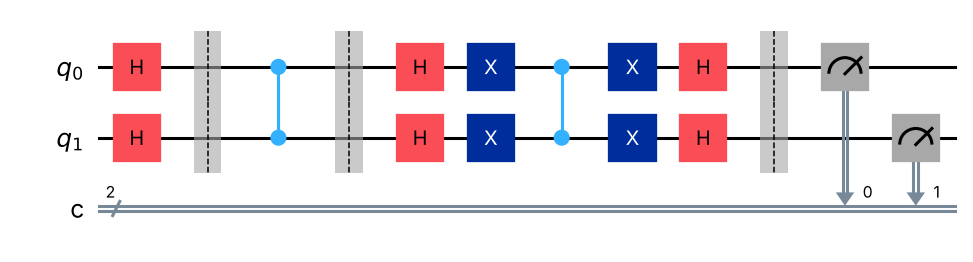

In [ ]:
toy = QuantumCircuit(2, 2)
toy.h([0, 1]); toy.barrier()
toy.cz(0, 1); toy.barrier()                                           # oracle
toy.h([0, 1]); toy.x([0, 1]); toy.cz(0, 1); toy.x([0, 1]); toy.h([0, 1]); toy.barrier()   # diffuser
toy.measure([0, 1], [0, 1])
print(AerSimulator().run(toy, shots=1000, seed_simulator=SEED).result().get_counts())
toy.draw('mpl')

## 4. Does it work? (noiseless)
Theory says P(valid) after k iterations = sin²((2k+1)θ), where sin²θ = M/N. We compute the exact simulated probability for each k and compare it with that formula.

largest gap between simulation and theory: 6.932232565759477e-13


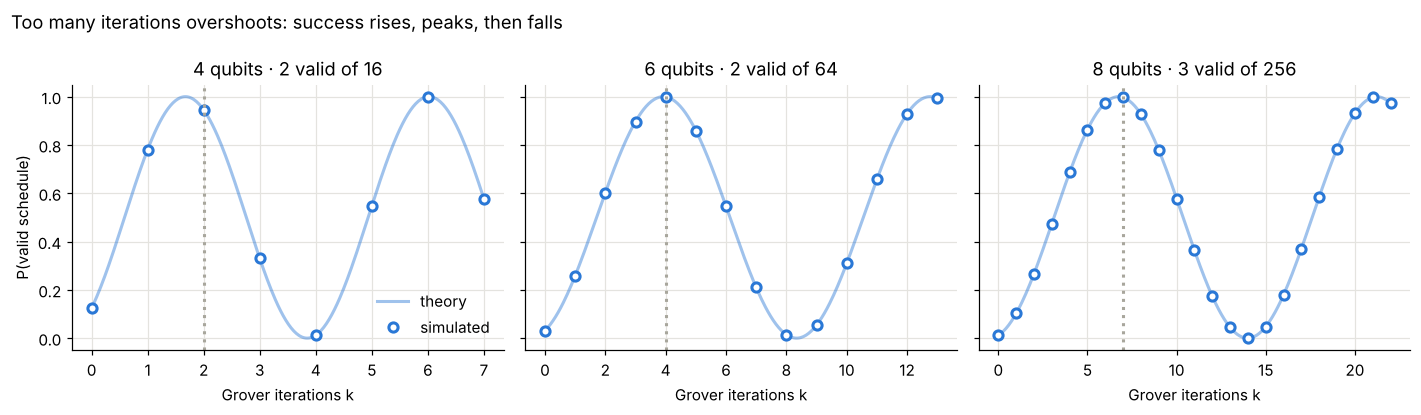

In [ ]:
def compile_grover(p, oracle, k, measure):
    return transpile(grover_circuit(p, oracle, k, measure=measure),
                     basis_gates=['u', 'cx'], optimization_level=3, seed_transpiler=0)

def theory(n, M, k):
    return sin((2 * k + 1) * asin(sqrt(M / 2 ** n))) ** 2

sweep = []
for n, make in INSTANCES.items():
    p = make(); M = len(valid_schedules(p)); o = build_oracle(p); kbest = known_iterations(n, M)
    for k in range(3 * kbest + 2):
        probs = np.abs(statevector(grover_circuit(p, o, k, measure=False))) ** 2
        sim = sum(probs[x] for x in valid_schedules(p))
        sweep.append({'qubits': n, 'k': k, 'best k': kbest, 'simulated': sim, 'theory': theory(n, M, k)})
sweep = pd.DataFrame(sweep); sweep.to_csv(OUT / 'iteration_sweep.csv', index=False)
print('largest gap between simulation and theory:', (sweep.simulated - sweep.theory).abs().max())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (n, d) in zip(axes, sweep.groupby('qubits')):
    M = sizes.set_index('qubits').loc[n, 'valid M']
    kk = np.linspace(0, d.k.max(), 300)
    ax.plot(kk, np.sin((2 * kk + 1) * np.arcsin(np.sqrt(M / 2 ** n))) ** 2, color=BLUE, alpha=.45, label='theory')
    ax.plot(d.k, d.simulated, 'o', color=BLUE, mfc='white', mew=2, label='simulated')
    ax.axvline(d['best k'].iloc[0], color=GRAY, ls=':')
    ax.set_title(f'{n} qubits · {M} valid of {2 ** n}'); ax.set_xlabel('Grover iterations k')
axes[0].set_ylabel('P(valid schedule)'); axes[0].legend(frameon=False)
fig.suptitle('Too many iterations overshoots: success rises, peaks, then falls', x=0.01, ha='left')
fig.tight_layout(); fig.savefig(OUT / 'iteration_sweep.png', dpi=200); plt.show()

Now actually measure it: 2,000 shots at the best k.

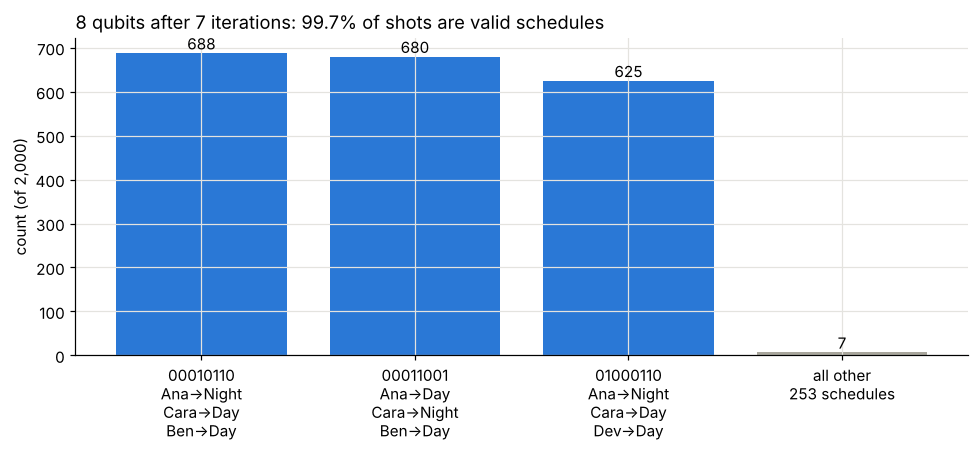

,qubits,best k,success,random guess,total qubits,CX per iteration,CX total,depth,expected Grover queries
0,4,2,0.9450,0.1250,8,440,880,1460,3.1746
1,6,4,0.9995,0.0312,11,1301,5240,8822,5.0025
2,8,7,0.9965,0.0117,13,2329,16537,30380,8.0281


In [ ]:
SHOTS = 2000
sim = AerSimulator(method='statevector')
runs, counts8 = [], None
for n, make in INSTANCES.items():
    p = make(); M = len(valid_schedules(p)); o = build_oracle(p); k = known_iterations(n, M)
    qc = compile_grover(p, o, k, measure=True)
    counts = sim.run(qc, shots=SHOTS, seed_simulator=SEED).result().get_counts()
    data_counts = {}
    for key, c in counts.items():
        x = int(key.replace(' ', ''), 2) & (2 ** n - 1)
        data_counts[x] = data_counts.get(x, 0) + c
    good = sum(c for x, c in data_counts.items() if p.feasible(x))
    one = compile_grover(p, o, 1, measure=False)
    runs.append({'qubits': n, 'best k': k, 'success': good / SHOTS, 'random guess': M / 2 ** n,
                 'total qubits': qc.num_qubits, 'CX per iteration': one.count_ops().get('cx', 0),
                 'CX total': qc.count_ops().get('cx', 0), 'depth': qc.depth(),
                 'expected Grover queries': (k + 1) / (good / SHOTS)})
    if n == 8: counts8 = data_counts
runs = pd.DataFrame(runs); runs.to_csv(OUT / 'grover_runs.csv', index=False)

valid8 = valid_schedules(p8)
labels = [f'{x:08b}\n{describe(p8, x)}'.replace(', ', '\n') for x in valid8] + ['all other\n253 schedules']
values = [counts8.get(x, 0) for x in valid8] + [SHOTS - sum(counts8.get(x, 0) for x in valid8)]
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(labels, values, color=[BLUE] * 3 + [GRAY])
ax.bar_label(bars); ax.set_ylabel('count (of 2,000)')
ax.set_title(f'8 qubits after 7 iterations: {sum(values[:3]) / SHOTS:.1%} of shots are valid schedules', loc='left')
fig.tight_layout(); fig.savefig(OUT / 'histogram_8q.png', dpi=200); plt.show()
runs.round(4)

## 5. Classical comparison
Same rules, three classical methods:
- **Brute force**: check whole schedules in random order. This is what Grover beats.
- **Backtracking**: fill in one decision at a time and drop a branch as soon as a rule can't be met.
- **CP-SAT**: Google's industrial constraint solver.

The units aren't identical (Grover oracle calls vs. partial schedules vs. solver branches), but "how many candidates did you have to look at" is a fair common measure.

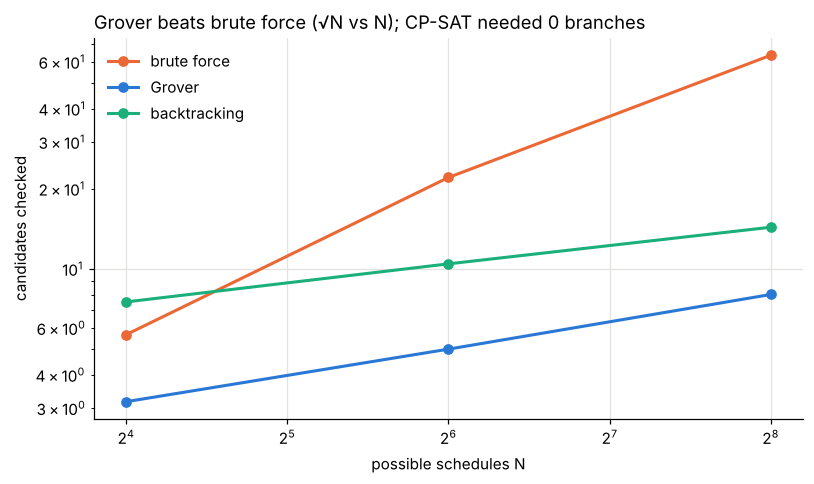

,qubits,N,brute force,Grover,backtracking,CP-SAT branches
0,4,16,5.7,3.2,7.5,0
1,6,64,22.1,5.0,10.5,0
2,8,256,63.6,8.0,14.4,0


In [ ]:
rng = random.Random(SEED)
comp = []
for n, make in INSTANCES.items():
    p = make(); r = runs.set_index('qubits').loc[n]
    comp.append({'qubits': n, 'N': 2 ** n,
                 'brute force': np.mean([brute_force_random(p, rng) for _ in range(5000)]),
                 'Grover': r['expected Grover queries'],
                 'backtracking': np.mean([backtracking(p, rng)[1] for _ in range(2000)]),
                 'CP-SAT branches': cpsat(p)['branches']})
comp = pd.DataFrame(comp); comp.to_csv(OUT / 'classical_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for col, color in [('brute force', ORANGE), ('Grover', BLUE), ('backtracking', AQUA)]:
    ax.plot(comp.N, comp[col], '-o', color=color, label=col)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xlabel('possible schedules N'); ax.set_ylabel('candidates checked')
ax.set_title('Grover beats brute force (√N vs N); CP-SAT needed 0 branches', loc='left')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(OUT / 'queries_vs_size.png', dpi=200); plt.show()
comp.round(1)

**The catch:** one Grover "check" is a whole oracle call, about 2,300 two-qubit gates at 8 qubits (table above). A classical check is a handful of CPU instructions.

## 6. Every rule makes the circuit bigger
We add the 11 rules one at a time to the 8-qubit problem and count CX (two-qubit) gates.

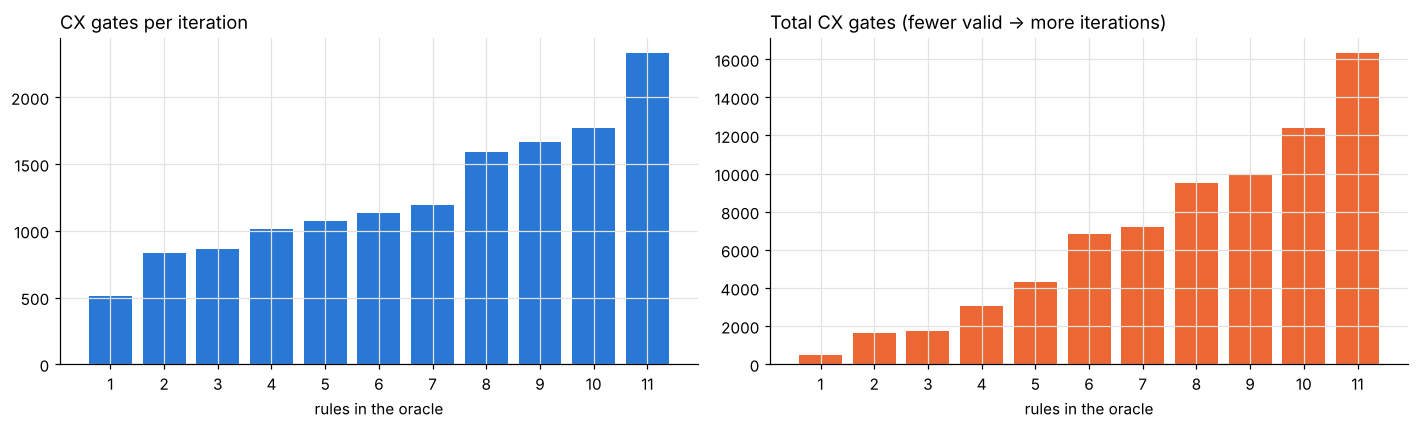

,rules,newest rule,valid M,best k,CX per iteration,CX total
0,1,day_headcount,96,1,509,509
1,2,night_headcount,24,2,830,1660
2,3,rn_on_day,20,2,866,1732
3,4,rn_on_night,10,3,1011,3033
4,5,no_double_Ana,7,4,1073,4292
5,6,no_double_Cara,4,6,1135,6810
6,7,no_double_Ben,4,6,1197,7182
7,8,no_double_Dev,4,6,1587,9522
8,9,Ben_unavailable_night,4,6,1667,10002
9,10,Ana_Dev_not_together_day,3,7,1771,12397


In [ ]:
ladder = []
for m in range(1, len(p8.rules) + 1):
    p = Problem(p8.assignments, p8.rules[:m]); M = len(valid_schedules(p)); o = build_oracle(p)
    k = known_iterations(8, M); one = compile_grover(p, o, 1, measure=False)
    ladder.append({'rules': m, 'newest rule': p8.rules[m - 1].name, 'valid M': M, 'best k': k,
                   'CX per iteration': one.count_ops().get('cx', 0)})
ladder = pd.DataFrame(ladder); ladder['CX total'] = ladder['CX per iteration'] * ladder['best k']
ladder.to_csv(OUT / 'constraint_ladder.csv', index=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.bar(ladder.rules, ladder['CX per iteration'], color=BLUE); a1.set_title('CX gates per iteration', loc='left')
a2.bar(ladder.rules, ladder['CX total'], color=ORANGE); a2.set_title('Total CX gates (fewer valid → more iterations)', loc='left')
for a in (a1, a2): a.set_xlabel('rules in the oracle'); a.set_xticks(ladder.rules)
fig.tight_layout(); fig.savefig(OUT / 'constraint_ladder.png', dpi=200); plt.show()
ladder

## 7. Noise
Real hardware makes mistakes. We add depolarizing noise to every gate, at rate p on two-qubit gates and p/10 on single-qubit gates. Today's best hardware is around p ≈ 10⁻³.

The simple model line assumes any error scrambles the answer: P ≈ F·P_ideal + (1−F)·M/N, where F is the chance of zero errors.

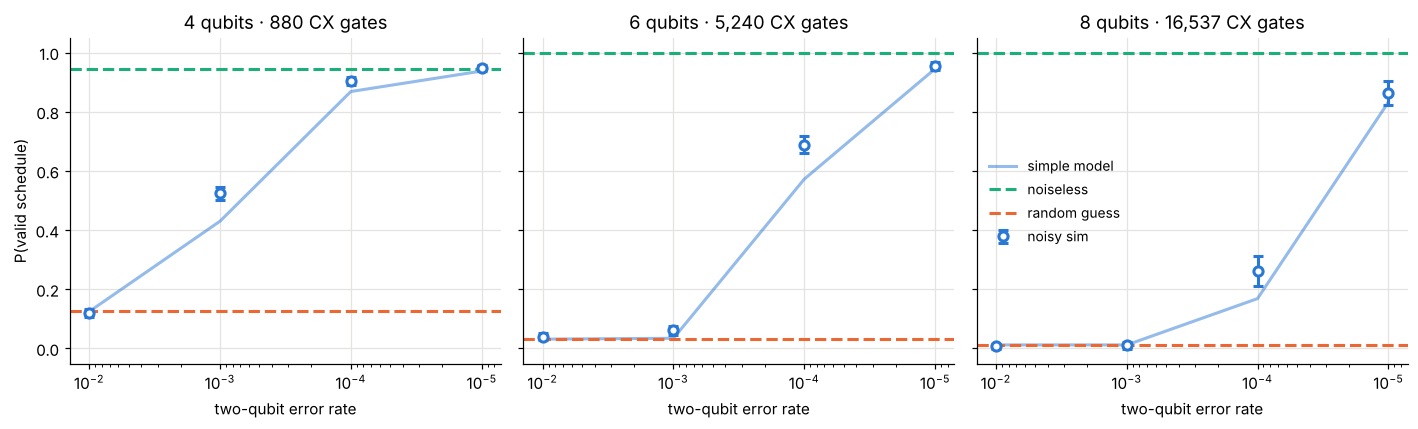

,qubits,error rate,shots,CX,success,ideal,random guess,model
0,4,1e-02,2000,880,0.119,0.945,0.125,0.125
1,4,1e-03,2000,880,0.523,0.945,0.125,0.430
2,4,1e-04,2000,880,0.903,0.945,0.125,0.868
3,4,1e-05,2000,880,0.949,0.945,0.125,0.937
4,6,1e-02,1000,"5,240",0.040,0.999,0.031,0.031
5,6,1e-03,1000,"5,240",0.062,0.999,0.031,0.034
6,6,1e-04,1000,"5,240",0.688,0.999,0.031,0.572
7,6,1e-05,1000,"5,240",0.954,0.999,0.031,0.944
8,8,1e-02,300,"16,537",0.007,0.997,0.012,0.012
9,8,1e-03,300,"16,537",0.010,0.997,0.012,0.012


In [ ]:
RATES = [1e-2, 1e-3, 1e-4, 1e-5]
noise_shots = {4: 2000, 6: 1000, 8: 100 if FAST else 300}
noise = []
for n, make in INSTANCES.items():
    p = make(); M = len(valid_schedules(p)); o = build_oracle(p); k = known_iterations(n, M)
    qc = compile_grover(p, o, k, measure=True)
    cx, u = qc.count_ops().get('cx', 0), qc.count_ops().get('u', 0)
    for rate in RATES:
        nm = NoiseModel()
        nm.add_all_qubit_quantum_error(depolarizing_error(rate / 10, 1), ['u'])
        nm.add_all_qubit_quantum_error(depolarizing_error(rate, 2), ['cx'])
        shots = noise_shots[n]
        counts = AerSimulator(method='statevector', noise_model=nm).run(qc, shots=shots, seed_simulator=SEED).result().get_counts()
        P = sum(c for key, c in counts.items() if p.feasible(int(key.replace(' ', ''), 2) & (2 ** n - 1))) / shots
        F = (1 - rate) ** cx * (1 - rate / 10) ** u
        noise.append({'qubits': n, 'error rate': rate, 'shots': shots, 'CX': cx, 'success': P,
                      'ideal': theory(n, M, k), 'random guess': M / 2 ** n,
                      'model': F * theory(n, M, k) + (1 - F) * M / 2 ** n})
noise = pd.DataFrame(noise); noise.to_csv(OUT / 'noise.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (n, d) in zip(axes, noise.groupby('qubits')):
    se = np.sqrt(d.success * (1 - d.success) / d.shots)
    ax.errorbar(d['error rate'], d.success, yerr=2 * se, fmt='o', color=BLUE, mfc='white', mew=2, capsize=3, label='noisy sim')
    ax.plot(d['error rate'], d.model, color=BLUE, alpha=.5, label='simple model')
    ax.axhline(d.ideal.iloc[0], color=AQUA, ls='--', label='noiseless')
    ax.axhline(d['random guess'].iloc[0], color=ORANGE, ls='--', label='random guess')
    ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('two-qubit error rate')
    ax.set_title(f'{n} qubits · {d.CX.iloc[0]:,} CX gates')
axes[0].set_ylabel('P(valid schedule)'); axes[-1].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(OUT / 'noise.png', dpi=200); plt.show()
noise.style.format({'error rate': '{:.0e}', 'success': '{:.3f}', 'ideal': '{:.3f}', 'random guess': '{:.3f}', 'model': '{:.3f}', 'CX': '{:,}'})

## 8. Real-size problems (classical only)
A real facility week: 7 days × 3 shifts, with coverage, an RN on every shift, no doubles, rest after nights, max 5 shifts a week, availability, and personnel conflicts. Grover would need one qubit per decision just to hold the schedule.

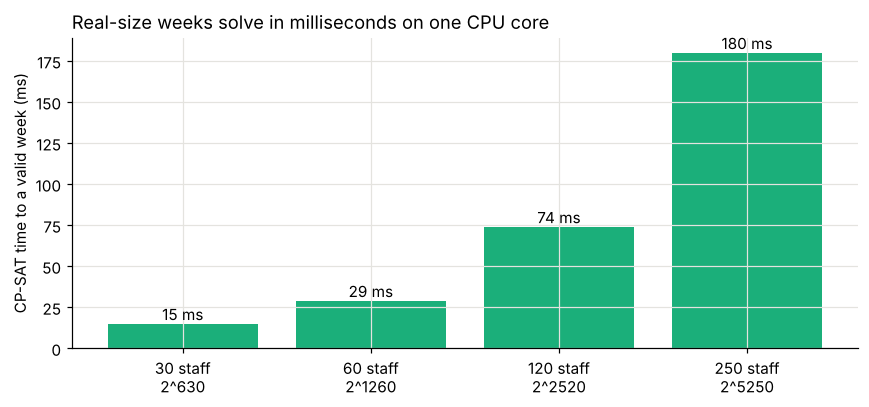

,staff,binary_variables,status,wall_seconds,branches
0,30,630,OPTIMAL,0.015,3045
1,60,1260,OPTIMAL,0.029,6116
2,120,2520,OPTIMAL,0.074,12413
3,250,5250,OPTIMAL,0.180,25614


In [ ]:
real = pd.DataFrame([real_size_cpsat(s, optimize=False) for s in (30, 60, 120, 250)])
real.to_csv(OUT / 'real_size_cpsat.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([f"{s} staff\n2^{v}" for s, v in zip(real.staff, real.binary_variables)], real.wall_seconds * 1000, color=AQUA)
for i, t in enumerate(real.wall_seconds * 1000): ax.text(i, t, f'{t:.0f} ms', ha='center', va='bottom')
ax.set_ylabel('CP-SAT time to a valid week (ms)')
ax.set_title('Real-size weeks solve in milliseconds on one CPU core', loc='left')
fig.tight_layout(); fig.savefig(OUT / 'real_size_cpsat.png', dpi=200); plt.show()
real[['staff', 'binary_variables', 'status', 'wall_seconds', 'branches']]

## 9. What it means
- **Grover works.** The simulation matches theory exactly, and it found a valid schedule 99.7% of the time at 8 qubits.
- **It beats brute force:** about 8 queries vs. 64 at N = 256, and the gap grows like √N vs. N.
- **But each query is huge:** about 2,300 two-qubit gates per iteration and 16,500 in total, and every added rule makes it bigger.
- **Noise kills it today:** at p = 10⁻³ the 8-qubit run is no better than guessing (≈1%). You need p ≈ 10⁻⁵ to get most of the way back, which means error-corrected hardware.
- **Classical already wins at real size:** CP-SAT solves real weeks with 2⁶³⁰+ possible schedules in milliseconds, and our toy instances in presolve.

**Recommendation:** Master Planner should pass on quantum scheduling for now and stick with classical solvers.

**What we can't claim:** simulator run time says nothing about real quantum speed, so we compared query counts and gate counts instead. The best iteration count uses the known number of valid schedules, which a real run wouldn't have. The noise model is generic, not a specific device.

## Credits
- Grover, *A fast quantum mechanical algorithm for database search* (1996): the algorithm.
- Qiskit and Qiskit Aer docs (QuantumCircuit, AerSimulator, noise models), and the Google OR-Tools CP-SAT docs.